# Laporan Praktikum Machine Learning: Clustering K-Means
## Studi Kasus: Segmentasi 200 Pelanggan Mall Berdasarkan Pendapatan Tahunan & Skor Belanja

**Mata Kuliah:** Machine Learning / Data Mining  
**Topik:** Unsupervised Learning - K-Means Clustering  
**Dataset:** `Clustering_KMeans_Mall_Customers.xlsx` (200 data pelanggan)  

---

### Deskripsi Tugas & Peran Manajer Mall
> *"Bayangkan kalian adalah seorang manajer mall. Kalian memiliki 200 data pelanggan. Setiap pelanggan memiliki informasi usia, pendapatan tahunan, dan skor belanja. Sebagai manajer, kalian ingin mengetahui karakteristik pelanggan agar dapat membuat strategi pemasaran yang tepat."*

Notebook ini menyajikan implementasi lengkap dan pengembangan tingkat lanjut dari materi dasar clustering pada praktikum:
1. **Eksplorasi Data (EDA)** dan statistik deskriptif 200 data pelanggan.
2. **Simulasi & Replikasi Perhitungan Manual Excel** (Iterasi 1 s.d. 4 hingga konvergen) dengan inisialisasi centroid C1=P13, C2=P16, C3=P167, C4=P172, C5=P81.
3. **Penentuan Jumlah Kluster Optimal (K)** menggunakan **Metode Elbow (WCSS)** dan **Analisis Silhouette Score**.
4. **Implementasi Scikit-Learn** dan pemetaan batas wilayah kluster (*Decision Boundary*).
5. **Profiling 5 Karakter Persona Pelanggan** dan **Rekomendasi Strategi Pemasaran Manajerial Mall**.

## 1. Import Library & Pengaturan Lingkungan

In [8]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Set style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 120

print("Library berhasil diimpor!")

Library berhasil diimpor!


## 2. Memuat Dataset dari File Excel (`Clustering_KMeans_Mall_Customers.xlsx`)

In [9]:
EXCEL_PATH = "Clustering_KMeans_Mall_Customers.xlsx"

# Baca Sheet 'DataAwal'
df_raw = pd.read_excel(EXCEL_PATH, sheet_name="DataAwal")
df = df_raw[['Pelanggan', 'Pendapatan Tahunan (k$)', 'Skor Belanja']].dropna()
df = df.rename(columns={
    'Pelanggan': 'pelanggan',
    'Pendapatan Tahunan (k$)': 'pendapatan_tahunan',
    'Skor Belanja': 'skor_belanja'
})

print(f"Total Data Pelanggan: {len(df)}")
display(df.head(10))
display(df.describe().T)

Total Data Pelanggan: 200


,pelanggan,pendapatan_tahunan,skor_belanja
0,P1,15,39
1,P2,15,81
2,P3,16,6
3,P4,16,77
4,P5,17,40
5,P6,17,76
6,P7,18,6
7,P8,18,94
8,P9,19,3
9,P10,19,72


,count,mean,std,min,25%,50%,75%,max
pendapatan_tahunan,200.0,60.56,26.264721,15.0,41.50,61.5,78.0,137.0
skor_belanja,200.0,50.20,25.823522,1.0,34.75,50.0,73.0,99.0


## 3. Exploratory Data Analysis (EDA)

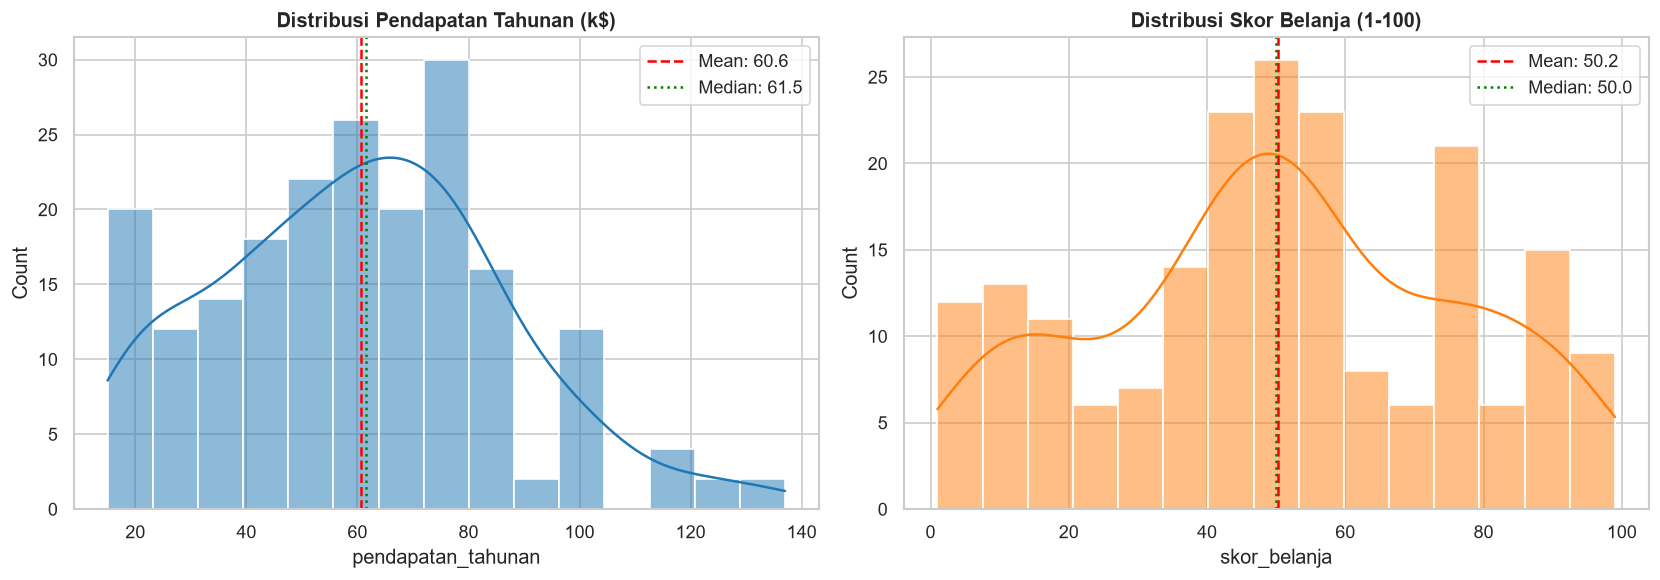

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi Pendapatan Tahunan
sns.histplot(df['pendapatan_tahunan'], kde=True, color='#1f77b4', bins=15, ax=axes[0])
axes[0].set_title('Distribusi Pendapatan Tahunan (k$)', fontsize=12, fontweight='bold')
axes[0].axvline(df['pendapatan_tahunan'].mean(), color='red', linestyle='--', label=f'Mean: {df["pendapatan_tahunan"].mean():.1f}')
axes[0].axvline(df['pendapatan_tahunan'].median(), color='green', linestyle=':', label=f'Median: {df["pendapatan_tahunan"].median():.1f}')
axes[0].legend()

# Distribusi Skor Belanja
sns.histplot(df['skor_belanja'], kde=True, color='#ff7f0e', bins=15, ax=axes[1])
axes[1].set_title('Distribusi Skor Belanja (1-100)', fontsize=12, fontweight='bold')
axes[1].axvline(df['skor_belanja'].mean(), color='red', linestyle='--', label=f'Mean: {df["skor_belanja"].mean():.1f}')
axes[1].axvline(df['skor_belanja'].median(), color='green', linestyle=':', label=f'Median: {df["skor_belanja"].median():.1f}')
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Replikasi & Validasi Perhitungan Manual Excel (Step-by-Step)
Pada sheet `Parameter` di file Excel, centroid awal yang dipilih adalah:
- **C1 (P13):** (20, 15)
- **C2 (P16):** (20, 79)
- **C3 (P167):** (86, 20)
- **C4 (P172):** (87, 75)
- **C5 (P81):** (54, 51)

Kita jalankan simulasi perulangan hingga konvergen dan bandingkan jumlah anggota tiap iterasi.

In [11]:
X = df[['pendapatan_tahunan', 'skor_belanja']].values

# Inisialisasi Centroid dari Excel
centroids = np.array([
    [20.0, 15.0],  # C1 (P13)
    [20.0, 79.0],  # C2 (P16)
    [86.0, 20.0],  # C3 (P167)
    [87.0, 75.0],  # C4 (P172)
    [54.0, 51.0]   # C5 (P81)
], dtype=float)

history = []
for it in range(1, 10):
    # Jarak Euclidean: ||x - c||
    dists = np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
    clusters = np.argmin(dists, axis=1) + 1  # 1-based indexing
    counts = {f'C{k}': int(np.sum(clusters == k)) for k in range(1, 6)}
    
    # Hitung centroid baru
    new_centroids = np.array([X[clusters == k].mean(axis=0) for k in range(1, 6)])
    history.append((it, counts, new_centroids))
    print(f"Iterasi {it}: Jumlah Anggota = {counts}")
    
    if np.allclose(centroids, new_centroids, atol=1e-5):
        print(f"\n>>> KONVERGENSI TERCAPAI PADA ITERASI {it}! <<<")
        break
    centroids = new_centroids.copy()

Iterasi 1: Jumlah Anggota = {'C1': 21, 'C2': 21, 'C3': 38, 'C4': 39, 'C5': 81}
Iterasi 2: Jumlah Anggota = {'C1': 22, 'C2': 22, 'C3': 37, 'C4': 39, 'C5': 80}
Iterasi 3: Jumlah Anggota = {'C1': 23, 'C2': 22, 'C3': 36, 'C4': 39, 'C5': 80}
Iterasi 4: Jumlah Anggota = {'C1': 23, 'C2': 22, 'C3': 36, 'C4': 39, 'C5': 80}

>>> KONVERGENSI TERCAPAI PADA ITERASI 4! <<<


### Visualisasi 4 Tahap Iterasi Manual Sesuai Excel

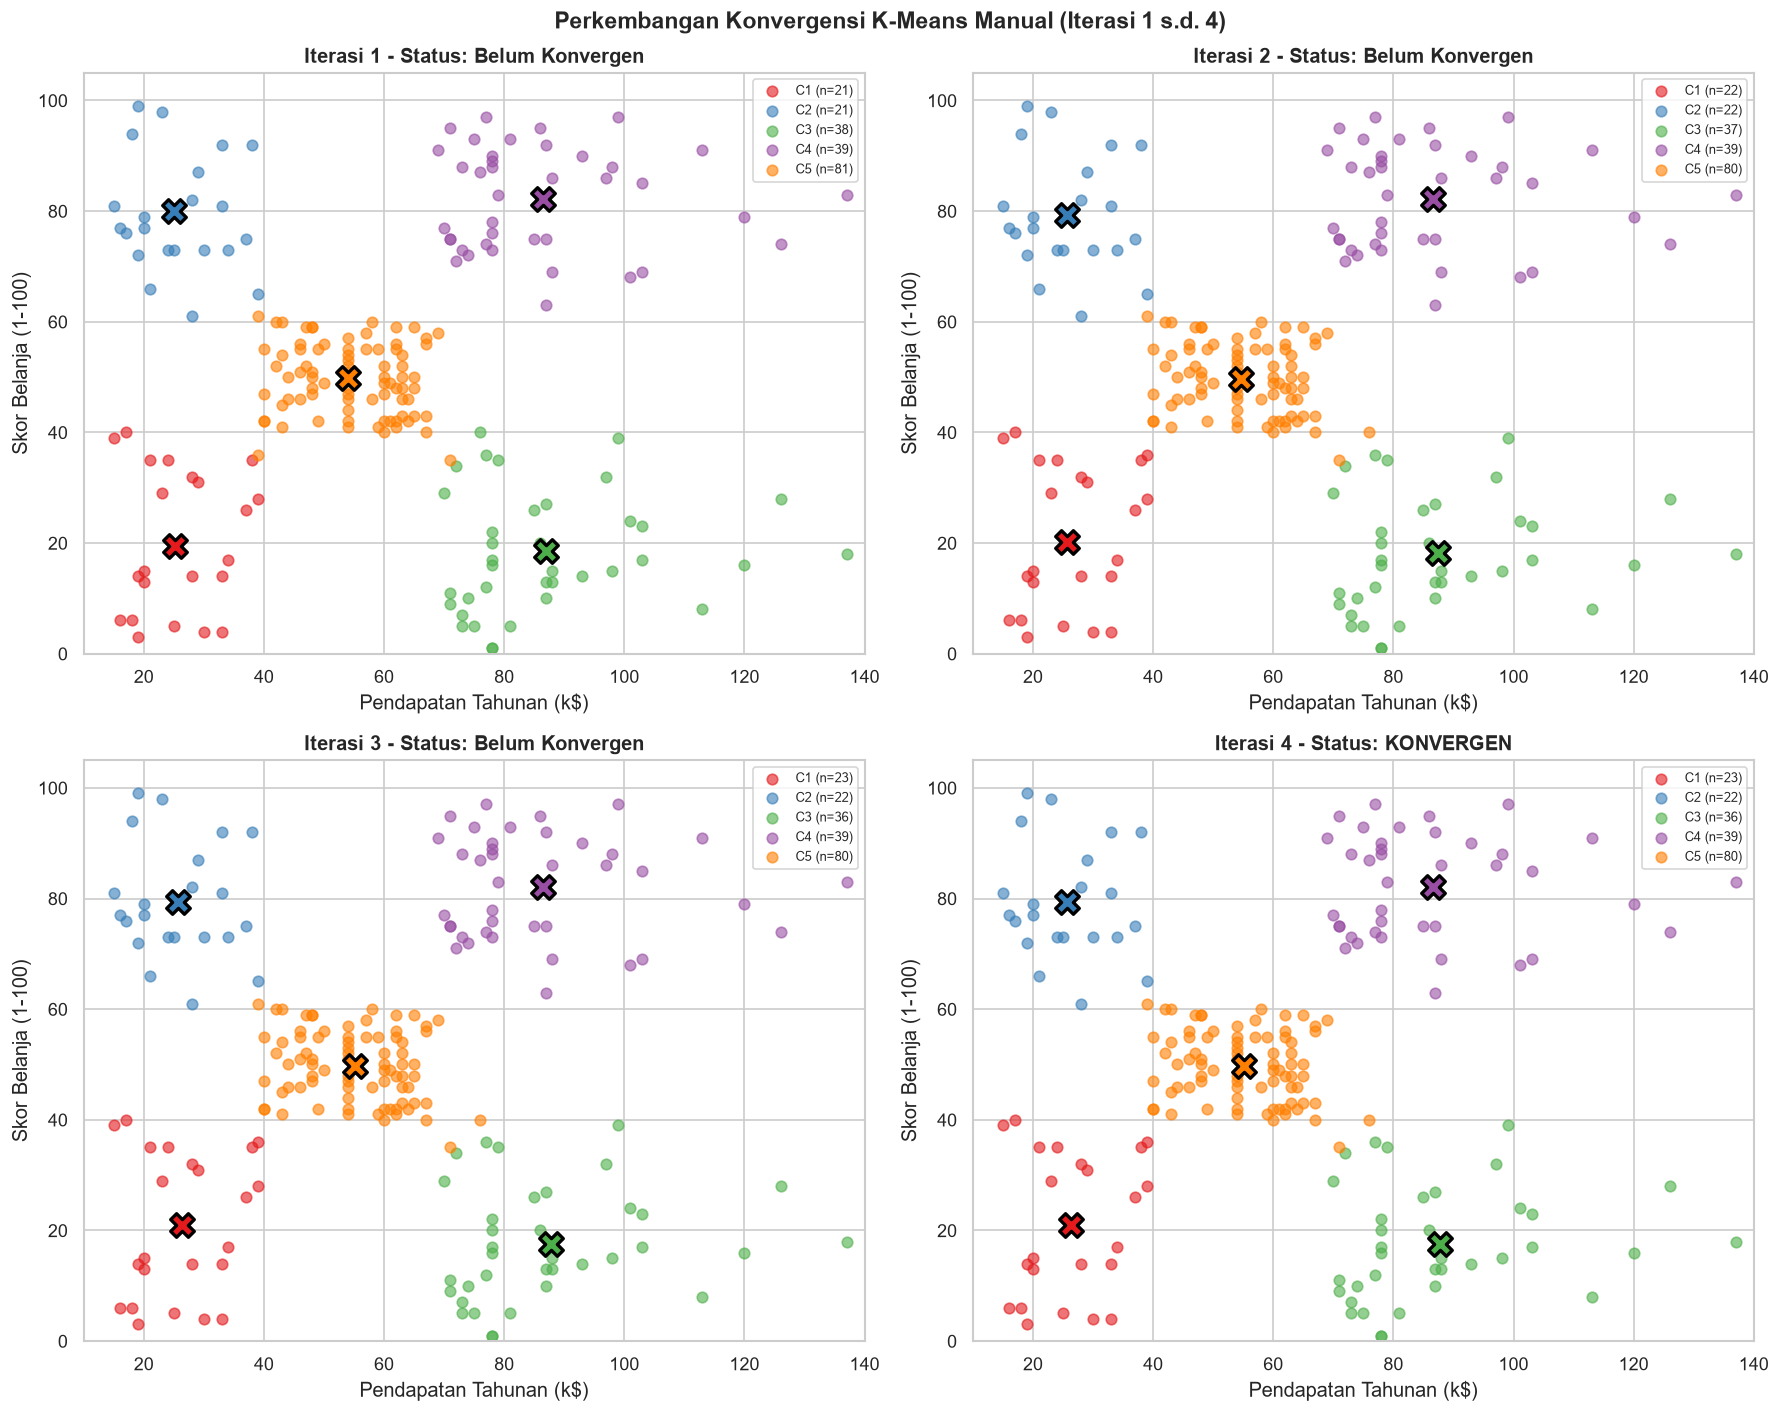

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes_flat = axes.flatten()
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']

for idx, (it_num, c_counts, c_coords) in enumerate(history[:4]):
    ax = axes_flat[idx]
    dists = np.linalg.norm(X[:, np.newaxis, :] - c_coords[np.newaxis, :, :], axis=2)
    cl_labels = np.argmin(dists, axis=1) + 1
    
    for k in range(1, 6):
        pts = X[cl_labels == k]
        ax.scatter(pts[:, 0], pts[:, 1], s=40, alpha=0.6, color=colors[k-1], label=f'C{k} (n={c_counts[f"C{k}"]})')
        ax.scatter(c_coords[k-1, 0], c_coords[k-1, 1], s=200, color=colors[k-1], 
                   edgecolor='black', linewidth=2, marker='X')
        
    status = "KONVERGEN" if it_num == len(history) else "Belum Konvergen"
    ax.set_title(f"Iterasi {it_num} - Status: {status}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Pendapatan Tahunan (k$)")
    ax.set_ylabel("Skor Belanja (1-100)")
    ax.set_xlim(10, 140)
    ax.set_ylim(0, 105)
    ax.legend(loc='upper right', fontsize=8)

plt.suptitle("Perkembangan Konvergensi K-Means Manual (Iterasi 1 s.d. 4)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Penentuan Jumlah Kluster Optimal (Metode Elbow & Silhouette Score)

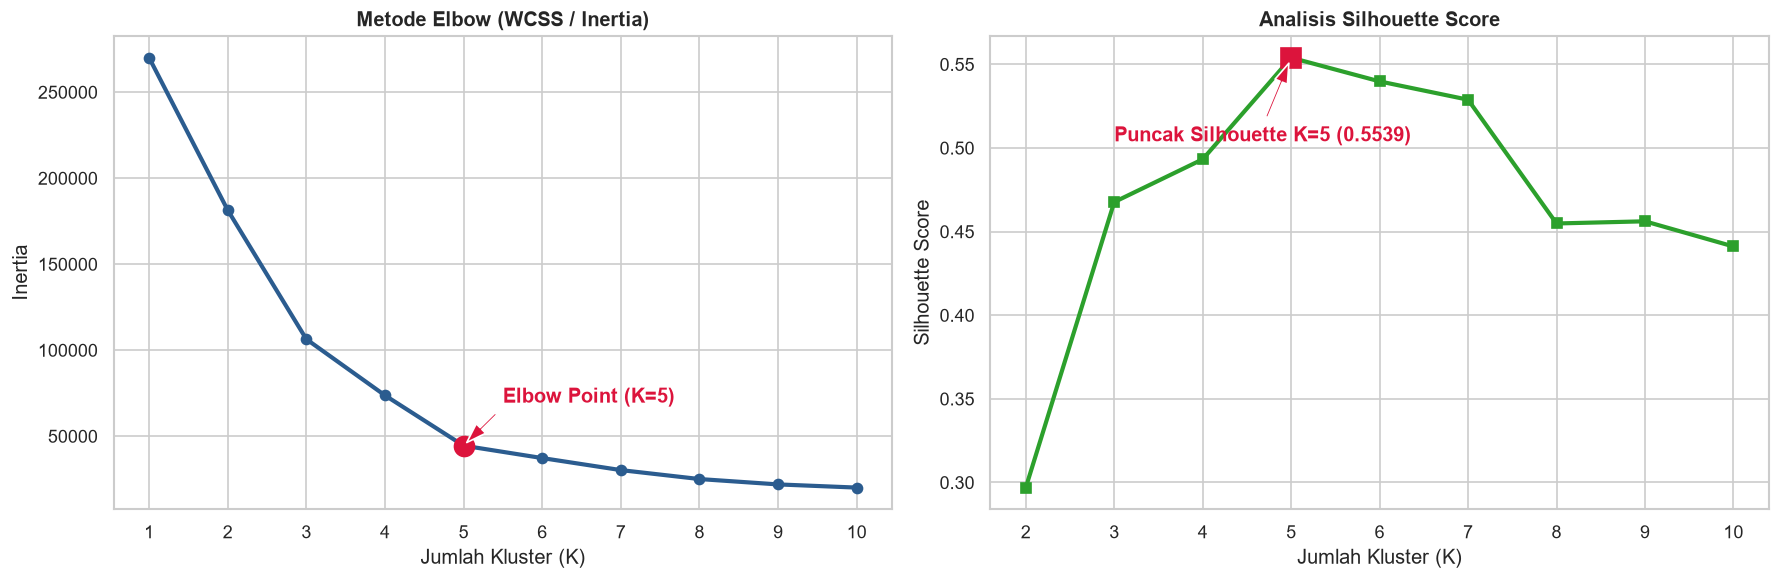

In [13]:
k_range = list(range(1, 11))
wcss = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)
    if k >= 2:
        sil = silhouette_score(X, km.labels_)
        sil_scores.append(sil)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Curve
axes[0].plot(k_range, wcss, marker='o', linewidth=2.5, color='#2b5c8f')
axes[0].plot(5, wcss[4], marker='o', markersize=12, color='crimson')
axes[0].annotate('Elbow Point (K=5)', xy=(5, wcss[4]), xytext=(5.5, wcss[4] + 25000),
                 arrowprops=dict(facecolor='crimson', shrink=0.08, width=1.5, headwidth=8),
                 fontweight='bold', color='crimson')
axes[0].set_title('Metode Elbow (WCSS / Inertia)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Kluster (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(k_range)

# Silhouette Score
axes[1].plot(list(range(2, 11)), sil_scores, marker='s', linewidth=2.5, color='#2ca02c')
axes[1].plot(5, sil_scores[3], marker='s', markersize=12, color='crimson')
axes[1].annotate(f'Puncak Silhouette K=5 ({sil_scores[3]:.4f})', xy=(5, sil_scores[3]), 
                 xytext=(3, sil_scores[3] - 0.05),
                 arrowprops=dict(facecolor='crimson', shrink=0.08, width=1.5, headwidth=8),
                 fontweight='bold', color='crimson')
axes[1].set_title('Analisis Silhouette Score', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Kluster (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(range(2, 11)))

plt.tight_layout()
plt.show()

## 6. Visualisasi Peta Segmentasi Pelanggan Akhir & Profil Kluster

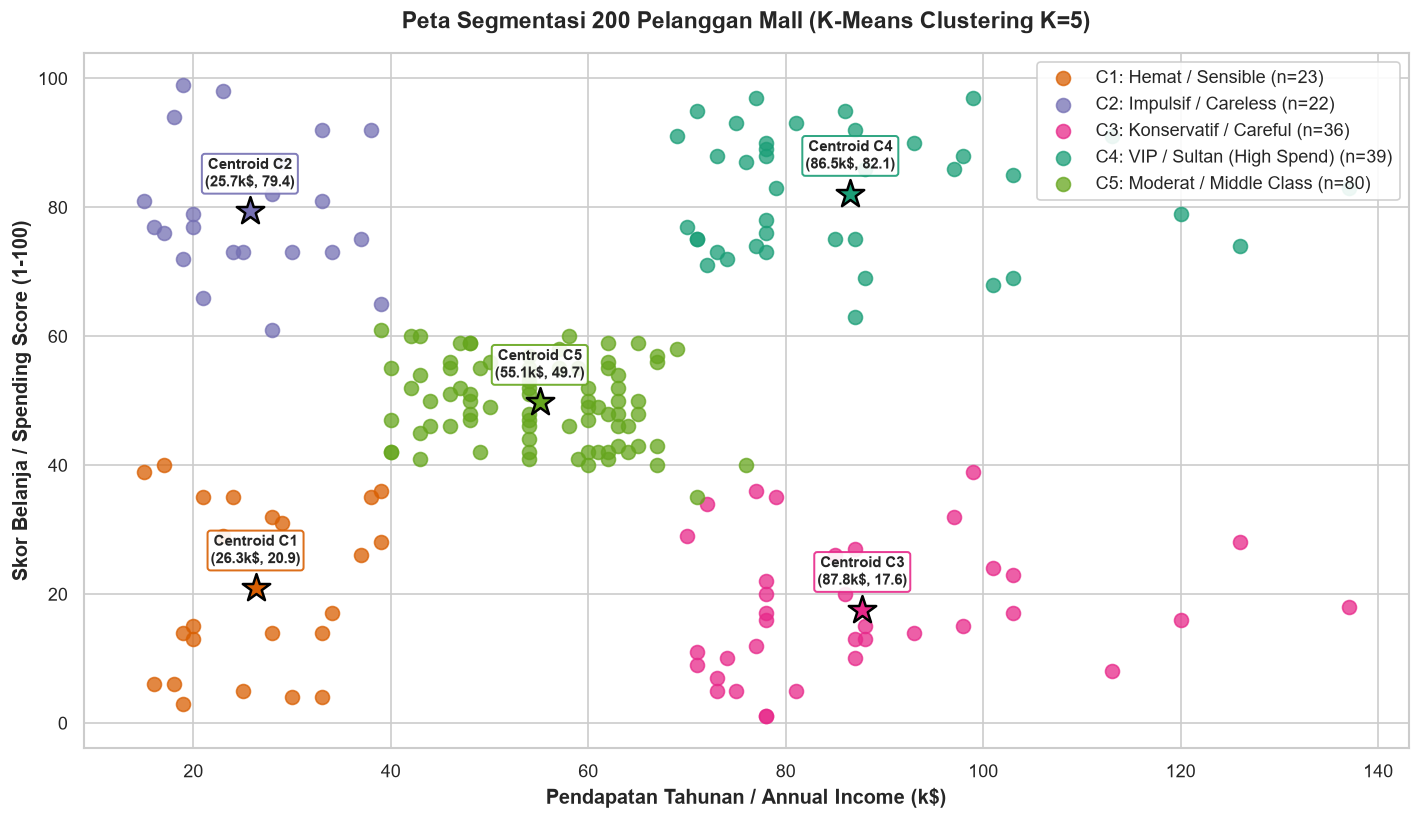

In [14]:
# Kluster Akhir dari Iterasi Konvergen
final_centroids = history[-1][2]
dists = np.linalg.norm(X[:, np.newaxis, :] - final_centroids[np.newaxis, :, :], axis=2)
df['kluster'] = np.argmin(dists, axis=1) + 1

segment_names = {
    1: ('C1: Hemat / Sensible', '#d95f02'),
    2: ('C2: Impulsif / Careless', '#7570b3'),
    3: ('C3: Konservatif / Careful', '#e7298a'),
    4: ('C4: VIP / Sultan (High Spend)', '#1b9e77'),
    5: ('C5: Moderat / Middle Class', '#66a61e')
}

plt.figure(figsize=(12, 7))
for k in range(1, 6):
    sub = df[df['kluster'] == k]
    name, col = segment_names[k]
    plt.scatter(sub['pendapatan_tahunan'], sub['skor_belanja'], s=70, alpha=0.75, color=col, label=f"{name} (n={len(sub)})")
    
    cx, cy = final_centroids[k-1]
    plt.scatter(cx, cy, s=300, marker='*', color=col, edgecolor='black', linewidth=1.5)
    plt.annotate(f"Centroid C{k}\n({cx:.1f}k$, {cy:.1f})", (cx, cy), xytext=(0, 15), textcoords="offset points",
                 ha='center', fontweight='bold', fontsize=9,
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=col, lw=1.2, alpha=0.9))

plt.title('Peta Segmentasi 200 Pelanggan Mall (K-Means Clustering K=5)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Pendapatan Tahunan / Annual Income (k$)', fontweight='bold')
plt.ylabel('Skor Belanja / Spending Score (1-100)', fontweight='bold')
plt.legend(loc='upper right', frameon=True, framealpha=0.9)
plt.tight_layout()
plt.show()

## 7. Rekomendasi Strategi Pemasaran Manajerial Mall

| Kluster | Segmen Pelanggan | Karakteristik Belanja | Tindakan / Strategi Pemasaran Manajerial |
| :--- | :--- | :--- | :--- |
| **C1** | **Hemat / Sensible Spender** | Pendapatan Rendah, Pengeluaran Rendah ($26.3k, skor 20.9) | Program diskon harga, voucher cashback belanja pokok, promo bundling hemat, event pasar murah. |
| **C2** | **Impulsif / Careless Spender** | Pendapatan Rendah, Pengeluaran Tinggi ($25.7k, skor 79.4) | Flash sale, opsi cicilan 0% / paylater, diskon tren fesyen & F&B kekinian, event bazaar weekend. |
| **C3** | **Konservatif / Careful Spender** | Pendapatan Tinggi, Pengeluaran Rendah ($87.8k, skor 17.6) | Promosi eksklusif produk berkualitas tinggi, garansi produk, direct marketing bernilai investasi. |
| **C4** | **VIP / Priority Spender (Sultan)** | Pendapatan Tinggi, Pengeluaran Tinggi ($86.5k, skor 82.1) | Membership tier VIP / Black Card, personal shopper, VIP lounge eksklusif, private preview collection, free valet parking. |
| **C5** | **Moderat / Middle Class** | Pendapatan Sedang, Pengeluaran Sedang ($55.1k, skor 49.7) | Program loyalitas poin berkala, seasonal sale (hari raya/tahun baru), promosi restoran & hiburan keluarga (bioskop). |